In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("../dataset/retail_sales_dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (1000, 9)


In [3]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB


In [5]:
df.dtypes

Transaction ID      int64
Date                  str
Customer ID           str
Gender                str
Age                 int64
Product Category      str
Quantity            int64
Price per Unit      int64
Total Amount        int64
dtype: object

In [6]:
df["Date"] = pd.to_datetime(df["Date"])

print("Date converted successfully!")
print(df["Date"].dtype)

Date converted successfully!
datetime64[us]


In [7]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


Customer Summary

In [9]:
customer_data = df.groupby("Customer ID").agg(
    Total_Purchases=("Total Amount", "sum"),
    Number_of_Transactions=("Transaction ID", "count"),
    Total_Quantity=("Quantity", "sum"),
    Average_Purchase_Value=("Total Amount", "mean")
).reset_index()

customer_data.head()

,Customer ID,Total_Purchases,Number_of_Transactions,Total_Quantity,Average_Purchase_Value
0,CUST001,150,1,3,150.0
1,CUST002,1000,1,2,1000.0
2,CUST003,30,1,1,30.0
3,CUST004,500,1,1,500.0
4,CUST005,100,1,2,100.0


In [10]:
print("Number of customers:", customer_data.shape[0])
print("Number of features:", customer_data.shape[1])

Number of customers: 1000
Number of features: 5


In [11]:
customer_data.describe()

,Total_Purchases,Number_of_Transactions,Total_Quantity,Average_Purchase_Value
count,1000.000000,1000.0,1000.000000,1000.000000
mean,456.000000,1.0,2.514000,456.000000
std,559.997632,0.0,1.132734,559.997632
min,25.000000,1.0,1.000000,25.000000
25%,60.000000,1.0,1.000000,60.000000
50%,135.000000,1.0,3.000000,135.000000
75%,900.000000,1.0,4.000000,900.000000
max,2000.000000,1.0,4.000000,2000.000000


Customer Behaviour Analysis

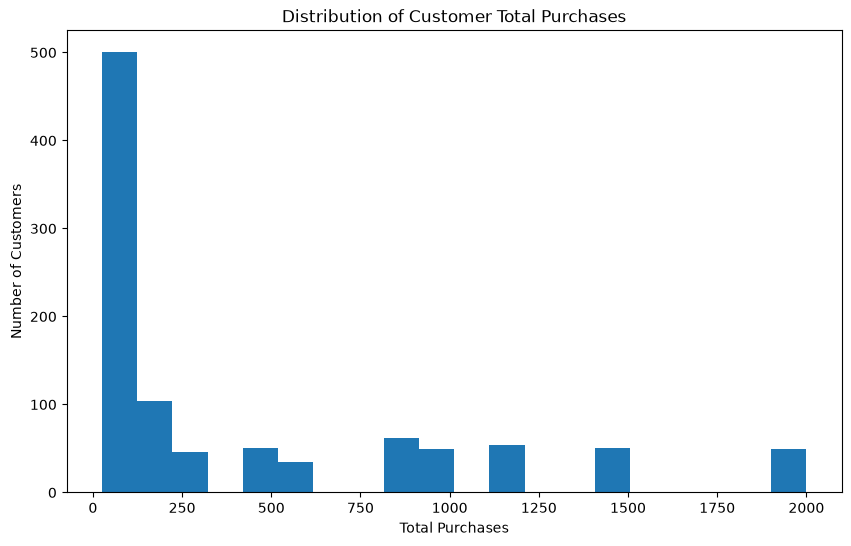

In [12]:
plt.figure(figsize=(10, 6))

plt.hist(customer_data["Total_Purchases"], bins=20)

plt.title("Distribution of Customer Total Purchases")
plt.xlabel("Total Purchases")
plt.ylabel("Number of Customers")

plt.show()

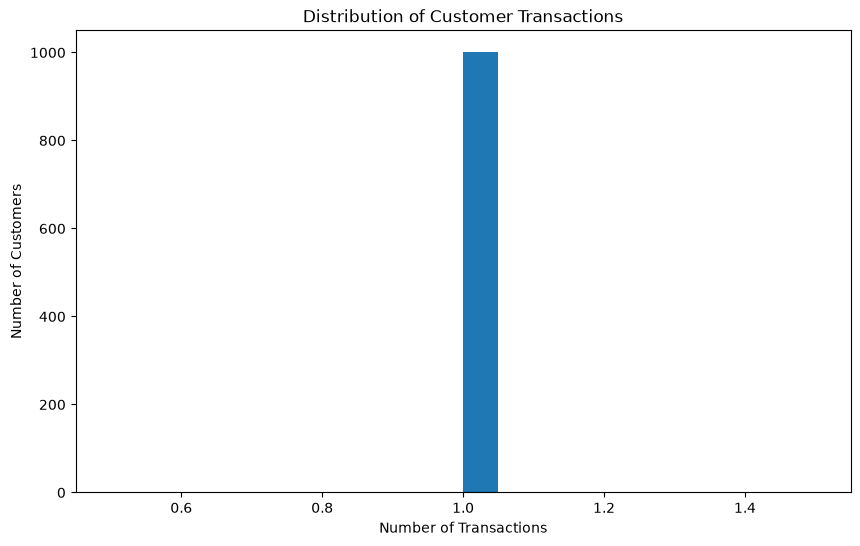

In [13]:
plt.figure(figsize=(10, 6))

plt.hist(customer_data["Number_of_Transactions"], bins=20)

plt.title("Distribution of Customer Transactions")
plt.xlabel("Number of Transactions")
plt.ylabel("Number of Customers")

plt.show()

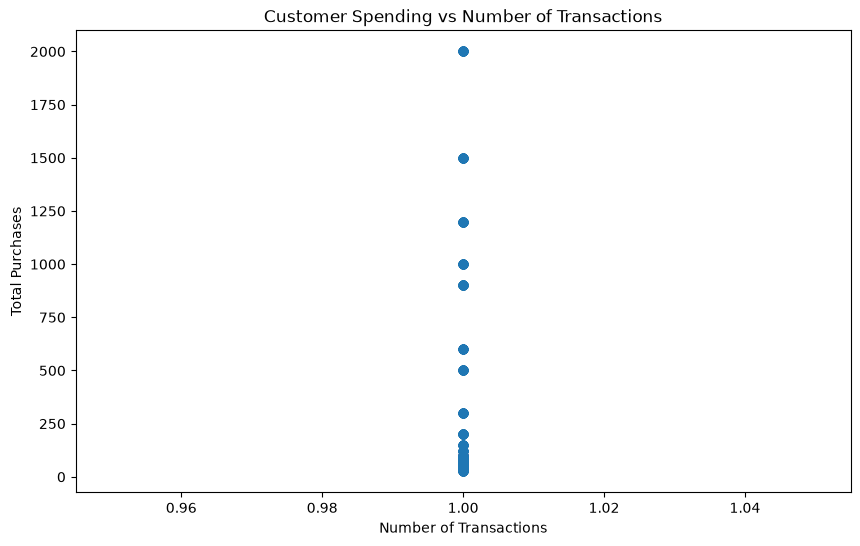

In [14]:
plt.figure(figsize=(10, 6))

plt.scatter(
    customer_data["Number_of_Transactions"],
    customer_data["Total_Purchases"]
)

plt.title("Customer Spending vs Number of Transactions")
plt.xlabel("Number of Transactions")
plt.ylabel("Total Purchases")

plt.show()

### Observation — Customer Behaviour

The customer behaviour analysis shows differences in total spending,
transaction frequency, and purchasing activity. Customers with more
transactions may generally contribute more to total purchases, while some
customers may have higher spending despite fewer transactions. These
differences provide a useful basis for customer segmentation.

Feature Scaling For K Means

In [15]:
features = [
    "Total_Purchases",
    "Number_of_Transactions",
    "Total_Quantity",
    "Average_Purchase_Value"
]

X = customer_data[features]

print("Features selected:")
print(X.head())

Features selected:
   Total_Purchases  Number_of_Transactions  Total_Quantity  \
0              150                       1               3   
1             1000                       1               2   
2               30                       1               1   
3              500                       1               1   
4              100                       1               2   

   Average_Purchase_Value  
0                   150.0  
1                  1000.0  
2                    30.0  
3                   500.0  
4                   100.0  


In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed!")
print("Scaled data shape:", X_scaled.shape)

Feature scaling completed!
Scaled data shape: (1000, 4)


In [17]:
X_scaled[:5]

array([[-0.5467043 ,  0.        ,  0.42926498, -0.5467043 ],
       [ 0.97191876,  0.        , -0.45399629,  0.97191876],
       [-0.76109815,  0.        , -1.33725757, -0.76109815],
       [ 0.07861108,  0.        , -1.33725757,  0.07861108],
       [-0.63603507,  0.        , -0.45399629, -0.63603507]])

Elbow Method

In [18]:
from sklearn.cluster import KMeans

In [19]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

print("Inertia values:")
print(inertia)

Inertia values:
[1244.147498774083, 626.6165574251997, 384.0814982699425, 286.6362866080275, 202.93484077874334, 146.81533000278355, 94.28376479841398, 59.11342249188638, 30.569480273143665]


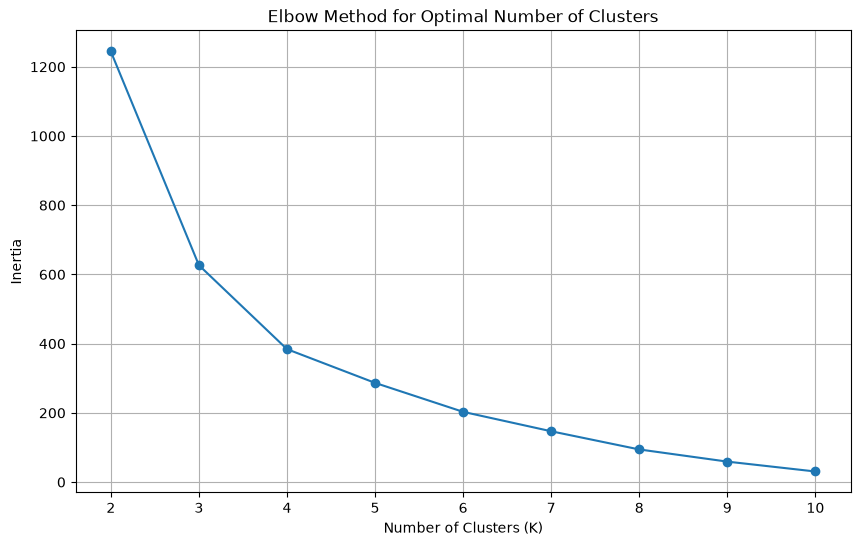

In [20]:
plt.figure(figsize=(10, 6))

plt.plot(range(2, 11), inertia, marker="o")

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

K-Means Clustering

In [21]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

customer_data["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed successfully!")

K-Means clustering completed successfully!


In [22]:
cluster_counts = customer_data["Cluster"].value_counts().sort_index()

print("Customers in each cluster:")
print(cluster_counts)

Customers in each cluster:
Cluster
0    289
1    153
2    146
3    412
Name: count, dtype: int64


Analyze Customer Segments

In [23]:
cluster_profile = customer_data.groupby("Cluster")[
    [
        "Total_Purchases",
        "Number_of_Transactions",
        "Total_Quantity",
        "Average_Purchase_Value"
    ]
].mean()

print(cluster_profile)

         Total_Purchases  Number_of_Transactions  Total_Quantity  \
Cluster                                                            
0             126.453287                     1.0        3.553633   
1            1554.248366                     1.0        3.673203   
2             861.643836                     1.0        2.424658   
3             135.570388                     1.0        1.385922   

         Average_Purchase_Value  
Cluster                          
0                    126.453287  
1                   1554.248366  
2                    861.643836  
3                    135.570388  


In [24]:
cluster_profile.round(2)

,Total_Purchases,Number_of_Transactions,Total_Quantity,Average_Purchase_Value
Cluster,,,,
0,126.45,1.0,3.55,126.45
1,1554.25,1.0,3.67,1554.25
2,861.64,1.0,2.42,861.64
3,135.57,1.0,1.39,135.57


In [25]:
highest_spending_cluster = cluster_profile["Total_Purchases"].idxmax()
lowest_spending_cluster = cluster_profile["Total_Purchases"].idxmin()

print("Highest spending cluster:", highest_spending_cluster)
print("Lowest spending cluster:", lowest_spending_cluster)

Highest spending cluster: 1
Lowest spending cluster: 0


Customer Segmentation Visualization

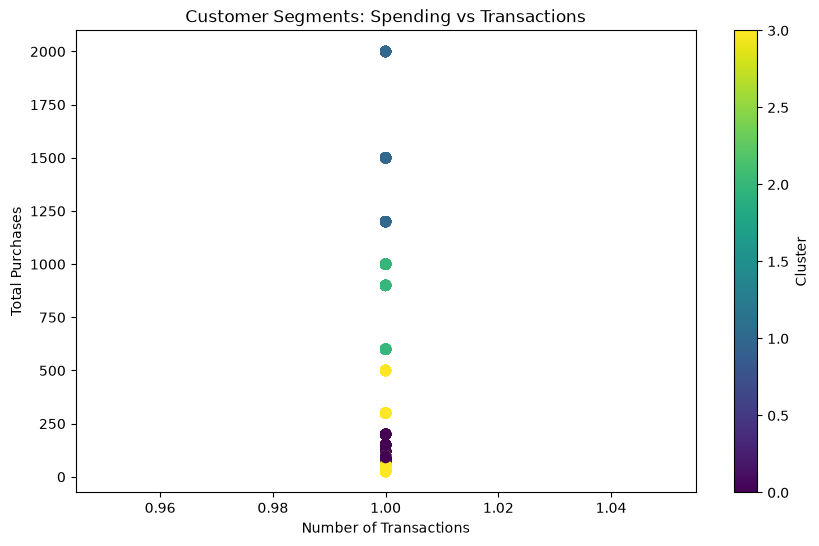

In [26]:
plt.figure(figsize=(10, 6))

plt.scatter(
    customer_data["Number_of_Transactions"],
    customer_data["Total_Purchases"],
    c=customer_data["Cluster"],
    cmap="viridis",
    s=50
)

plt.title("Customer Segments: Spending vs Transactions")
plt.xlabel("Number of Transactions")
plt.ylabel("Total Purchases")
plt.colorbar(label="Cluster")

plt.show()

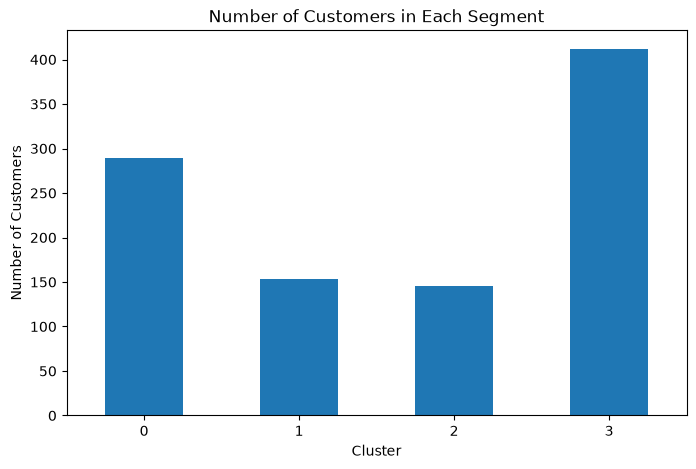

In [27]:
plt.figure(figsize=(8, 5))

cluster_counts.plot(kind="bar")

plt.title("Number of Customers in Each Segment")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.show()

### Observation — Customer Segments

The K-Means clustering analysis divided customers into four distinct
segments based on their purchasing behaviour. The segments differ in
transaction frequency and total spending. Cluster 1 represents the
highest-spending group, while Cluster 0 represents the lowest-spending
group. The visualization helps compare the size and behaviour of the
different customer segments.

Understand the 4 Segments

In [28]:
cluster_profile.round(2)

,Total_Purchases,Number_of_Transactions,Total_Quantity,Average_Purchase_Value
Cluster,,,,
0,126.45,1.0,3.55,126.45
1,1554.25,1.0,3.67,1554.25
2,861.64,1.0,2.42,861.64
3,135.57,1.0,1.39,135.57


In [29]:
print("Customer count by cluster:")
print(cluster_counts)

Customer count by cluster:
Cluster
0    289
1    153
2    146
3    412
Name: count, dtype: int64


Name the Customer Segments

In [30]:
# Get clusters ordered by total spending
spending_order = cluster_profile["Total_Purchases"].sort_values().index

# Assign meaningful names from lowest to highest spending
segment_names = {
    spending_order[0]: "Low-Value Customers",
    spending_order[1]: "Medium-Low Value Customers",
    spending_order[2]: "Medium-High Value Customers",
    spending_order[3]: "High-Value Customers"
}

customer_data["Customer Segment"] = customer_data["Cluster"].map(segment_names)

print(customer_data[["Customer ID", "Cluster", "Customer Segment"]].head(10))

  Customer ID  Cluster             Customer Segment
0     CUST001        0          Low-Value Customers
1     CUST002        2  Medium-High Value Customers
2     CUST003        3   Medium-Low Value Customers
3     CUST004        3   Medium-Low Value Customers
4     CUST005        3   Medium-Low Value Customers
5     CUST006        3   Medium-Low Value Customers
6     CUST007        3   Medium-Low Value Customers
7     CUST008        0          Low-Value Customers
8     CUST009        2  Medium-High Value Customers
9     CUST010        0          Low-Value Customers


In [31]:
final_segment_profile = customer_data.groupby("Customer Segment").agg(
    Customers=("Customer ID", "count"),
    Average_Total_Purchases=("Total_Purchases", "mean"),
    Average_Transactions=("Number_of_Transactions", "mean"),
    Average_Quantity=("Total_Quantity", "mean"),
    Average_Purchase_Value=("Average_Purchase_Value", "mean")
).round(2)

print(final_segment_profile)

                             Customers  Average_Total_Purchases  \
Customer Segment                                                  
High-Value Customers               153                  1554.25   
Low-Value Customers                289                   126.45   
Medium-High Value Customers        146                   861.64   
Medium-Low Value Customers         412                   135.57   

                             Average_Transactions  Average_Quantity  \
Customer Segment                                                      
High-Value Customers                          1.0              3.67   
Low-Value Customers                           1.0              3.55   
Medium-High Value Customers                   1.0              2.42   
Medium-Low Value Customers                    1.0              1.39   

                             Average_Purchase_Value  
Customer Segment                                     
High-Value Customers                        1554.25  
Low-Valu

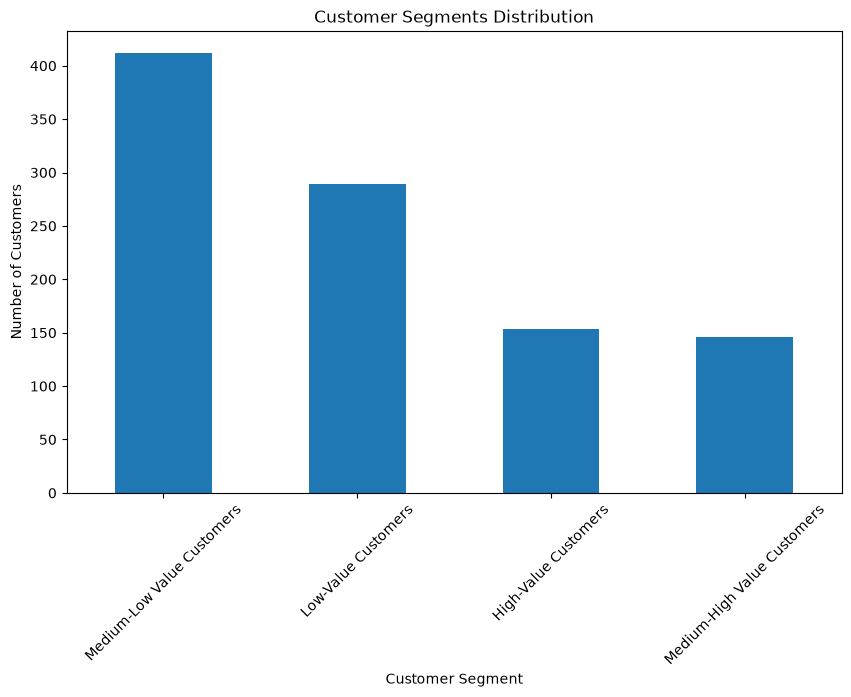

In [32]:
segment_counts = customer_data["Customer Segment"].value_counts()

plt.figure(figsize=(10, 6))

segment_counts.plot(kind="bar")

plt.title("Customer Segments Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.show()

### Observation — Final Customer Segments

The K-Means analysis divided customers into four segments based on their
purchasing behaviour. The segments range from low-value to high-value
customers according to their total spending. These segments can help the
business understand different customer groups and develop targeted
marketing and retention strategies.

Business recommendations

## Business Recommendations

1. **High-Value Customers:** Provide loyalty rewards, personalized offers,
   and premium promotions to retain high-value customers.

2. **Medium-High Value Customers:** Use targeted promotions and cross-selling
   strategies to encourage these customers to increase their spending.

3. **Medium-Low Value Customers:** Offer personalized discounts and product
   recommendations to increase purchase frequency and transaction value.

4. **Low-Value Customers:** Use introductory offers and engagement campaigns
   to encourage repeat purchases and improve customer retention.

5. **Monitor Customer Segments:** Regularly update the segmentation analysis
   to identify customers whose purchasing behaviour changes over time.

# Conclusion

The customer segmentation analysis used K-Means clustering to divide
customers into four groups based on their purchasing behaviour. Customer
spending, transaction frequency, total quantity purchased, and average
purchase value were used to identify differences between customer groups.

The four segments range from low-value to high-value customers. The
segmentation provides a useful way to understand customer behaviour and
develop targeted marketing strategies.

## Key Business Insights

1. Customers have different purchasing patterns and spending levels.
2. High-value customers should receive greater retention and loyalty
   attention.
3. Lower-value customers represent an opportunity for targeted promotions
   and increased engagement.
4. Medium-value customers can be encouraged to increase their purchase
   frequency and transaction value.

## Business Impact

Customer segmentation can help businesses personalize marketing campaigns,
improve customer retention, identify valuable customer groups, and develop
strategies to increase customer lifetime value.